# Cross-CE Peak Consistency Analysis

For each `group_id` (mol + adduct + inst_type), spectra at different CEs should share fragment peaks.
A peak appearing at an m/z absent from all other CE spectra in the group is labelled **orphan**.

Questions to answer:
1. What fraction of peaks are orphans overall, by inst_type, by adduct?
2. Are orphans concentrated in low-intensity peaks (noise) or high-intensity ones?
3. Does orphan rate increase with CE level (high CE = more diverse fragmentation)?
4. What is the orphan rate distribution as a function of group size (number of CE spectra)?

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fragnnet.utils.data_utils import parse_peaks_str, convert_peaks_to_float
from fragnnet.utils.isotope_utils import detect_cross_ce_orphan_peaks

In [2]:
# ── Configure path to processed NIST 20hr proc directory ──────────────────
PROC_DP = "../../data/proc/nist20"  # <-- set this
dset = "nist20_hr"
spec_df = pd.read_pickle(os.path.join(PROC_DP, "spec_df.pkl"))
spec_df = spec_df[spec_df['dset'] == dset]
spec_df = spec_df[spec_df['prec_type'].isin(['[M+H]+', '[M-H]-', '[M+Na]+', '[M+K]+'])]
spec_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,nce,prec_mz,peaks,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ce_type
7,7,10998,[M+Na]+,QTOF,CID,MS2,P,nist20_hr,1035180,N2,...,NaN,1471.9614,"[(599.5, 41.06), (873.47, 47.75), (1470.95, 86...",NaN,1,NaN,NaN,NaN,NaN,single
8,8,10998,[M+Na]+,QTOF,CID,MS2,P,nist20_hr,1035181,N2,...,NaN,1471.9614,"[(599.49, 52.95), (601.51, 54.15), (873.46, 13...",NaN,1,NaN,NaN,NaN,NaN,single
9,9,10998,[M+Na]+,QTOF,CID,MS2,P,nist20_hr,1035182,N2,...,NaN,1471.9614,"[(274.97, 74.23), (599.5, 79.22), (601.52, 50....",NaN,1,NaN,NaN,NaN,NaN,single
15,15,10998,[M-H]-,QTOF,CID,MS2,N,nist20_hr,1035201,N2,...,NaN,1447.9649,"[(29.69, 24.38), (279.24, 44.56), (415.23, 34....",NaN,4,NaN,NaN,NaN,NaN,single
16,16,10998,[M-H]-,QTOF,CID,MS2,N,nist20_hr,1035202,N2,...,NaN,1447.9649,"[(153.0, 26.67), (279.24, 45.45), (415.23, 31....",NaN,4,NaN,NaN,NaN,NaN,single


In [3]:
print(f"Loaded {len(spec_df):,} spectra")
print(spec_df.dtypes[[c for c in ['group_id','mol_id','prec_type','inst_type','ace','nce','peaks'] if c in spec_df.columns]])

Loaded 474,217 spectra
group_id       int64
mol_id         int64
prec_type     object
inst_type     object
ace          float64
nce          float64
peaks         object
dtype: object


In [4]:
# ── Parse peaks into (mzs, ints) arrays ──────────────────────────────────
# peaks column is a list of (mz, intensity) float tuples after proc
def to_arrays(peaks):
    if not peaks:
        return np.array([], dtype=np.float64), np.array([], dtype=np.float64)
    mzs, ints = zip(*peaks)
    return np.array(mzs, dtype=np.float64), np.array(ints, dtype=np.float64)

spec_df['_mzs'] = spec_df['peaks'].apply(lambda p: to_arrays(p)[0])
spec_df['_ints'] = spec_df['peaks'].apply(lambda p: to_arrays(p)[1])
print("Peak arrays parsed")

Peak arrays parsed


In [5]:
# ── Keep only groups with ≥2 spectra (need multiple CEs to compare) ───────
group_sizes = spec_df.groupby('group_id').size()
multi_ce_groups = group_sizes[group_sizes >= 2].index
df = spec_df[spec_df['group_id'].isin(multi_ce_groups)].copy()
print(f"Groups with ≥2 CE spectra: {len(multi_ce_groups):,}")
print(f"Spectra in those groups:   {len(df):,}")
print(f"\nGroup size distribution:")
print(group_sizes[group_sizes >= 2].value_counts().sort_index().head(10))

Groups with ≥2 CE spectra: 40,012
Spectra in those groups:   438,792

Group size distribution:
2     1121
3     1051
4     1284
5     2022
6     1890
7     1878
8     2112
9     2417
10    3025
11    3434
Name: count, dtype: int64


In [ ]:
from tqdm import tqdm

# ── Run orphan detection per group ───────────────────────────────────────
records = []  # one record per peak

for group_id, grp in tqdm(df.groupby('group_id'), total=len(df.groupby('group_id')), desc='Processing groups'):
    inst_type = grp['inst_type'].iloc[0]
    peaks_list = [(row['_mzs'], row['_ints']) for _, row in grp.iterrows()]
    orphan_masks = detect_cross_ce_orphan_peaks(peaks_list, inst_type=inst_type)

    for (_, row), mask in zip(grp.iterrows(), orphan_masks):
        mzs, ints = row['_mzs'], row['_ints']
        if len(mzs) == 0:
            continue
        base_int = ints.max() if len(ints) > 0 else 1.0
        for mz, intensity, is_orphan in zip(mzs, ints, mask):
            records.append({
                'spec_id': row['spec_id'],
                'group_id': group_id,
                'inst_type': inst_type,
                'prec_type': row['prec_type'],
                'ace': row.get('ace', np.nan),
                'nce': row.get('nce', np.nan),
                'group_size': len(grp),
                'mz': mz,
                'intensity': intensity,
                'rel_intensity': intensity / base_int if base_int > 0 else 0.0,
                'is_orphan': bool(is_orphan),
            })

peak_df = pd.DataFrame(records)
print(f"Total peaks analysed: {len(peak_df):,}")
print(f"Orphan peaks:         {peak_df['is_orphan'].sum():,}  ({100*peak_df['is_orphan'].mean():.1f}%)")

Processing groups:  49%|████▉     | 19605/40012 [02:38<02:04, 164.15it/s]

           orphan_rate  orphan_count  total_peaks
inst_type                                        
QTOF             0.059         30991       524518
FT               0.030        413782     14003279


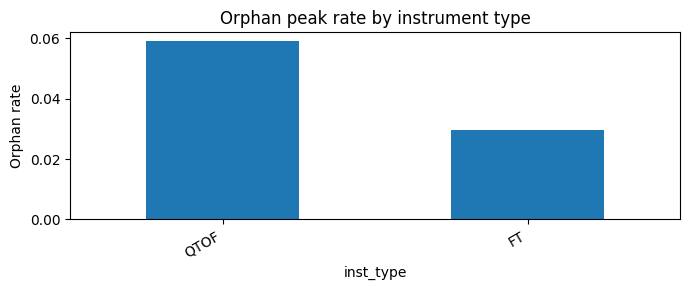

In [ ]:
# ── 1. Orphan rate by inst_type ──────────────────────────────────────────
inst_stats = peak_df.groupby('inst_type')['is_orphan'].agg(['mean','sum','count'])
inst_stats.columns = ['orphan_rate', 'orphan_count', 'total_peaks']
inst_stats = inst_stats.sort_values('orphan_rate', ascending=False)
print(inst_stats.round(3))

fig, ax = plt.subplots(figsize=(7, 3))
inst_stats['orphan_rate'].plot.bar(ax=ax)
ax.set_ylabel('Orphan rate')
ax.set_title('Orphan peak rate by instrument type')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

           orphan_rate  total_peaks
prec_type                          
[M+K]+           0.091        18814
[M+Na]+          0.075       877789
[M+H]+           0.028      9999652
[M-H]-           0.028      3631542


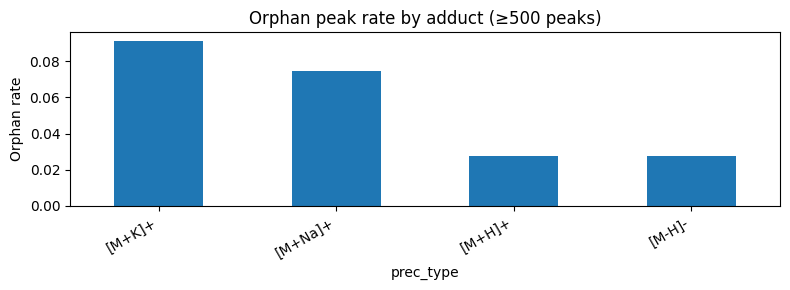

In [ ]:
# ── 2. Orphan rate by adduct (prec_type) ─────────────────────────────────
adduct_stats = (
    peak_df.groupby('prec_type')['is_orphan']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'orphan_rate', 'count': 'total_peaks'})
    .query('total_peaks >= 500')
    .sort_values('orphan_rate', ascending=False)
    .head(15)
)
print(adduct_stats.round(3))

fig, ax = plt.subplots(figsize=(8, 3))
adduct_stats['orphan_rate'].plot.bar(ax=ax)
ax.set_ylabel('Orphan rate')
ax.set_title('Orphan peak rate by adduct (≥500 peaks)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

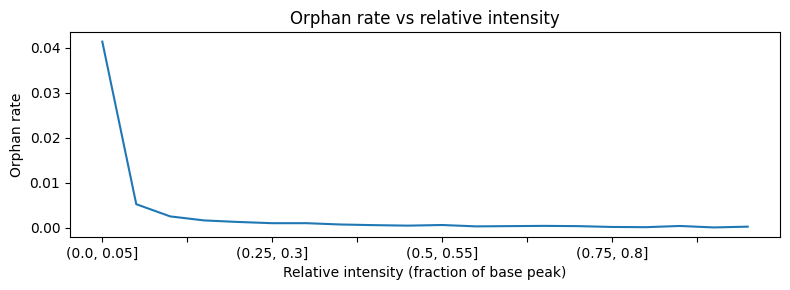

In [ ]:
# ── 3. Orphan rate vs relative intensity ─────────────────────────────────
# Orphans should be enriched in low-intensity bins if they are noise/artefacts.
bins = np.linspace(0, 1, 21)
peak_df['rel_int_bin'] = pd.cut(peak_df['rel_intensity'], bins=bins)
int_stats = peak_df.groupby('rel_int_bin', observed=True)['is_orphan'].mean()

fig, ax = plt.subplots(figsize=(8, 3))
int_stats.plot(ax=ax)
ax.set_xlabel('Relative intensity (fraction of base peak)')
ax.set_ylabel('Orphan rate')
ax.set_title('Orphan rate vs relative intensity')
plt.tight_layout()
plt.show()

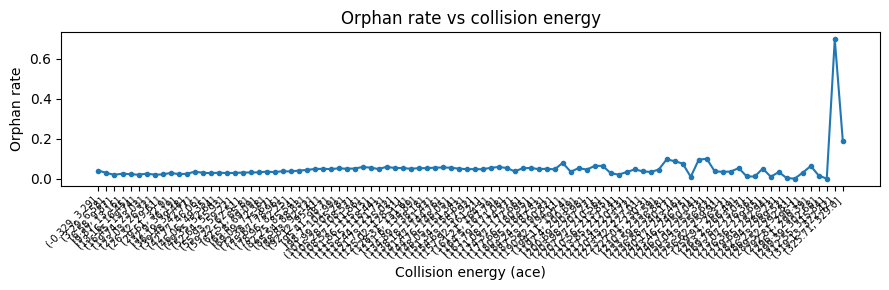

In [ ]:
# ── 4. Orphan rate vs collision energy (ACE) ─────────────────────────────
ce_col = 'ace' if peak_df['ace'].notna().any() else 'nce'
ce_data = peak_df[peak_df[ce_col].notna()].copy()

if len(ce_data) > 0:
    ce_data['ce_bin'] = pd.cut(ce_data[ce_col], bins=100)
    ce_stats = ce_data.groupby('ce_bin', observed=True)['is_orphan'].agg(['mean', 'count'])
    ce_stats.columns = ['orphan_rate', 'n_peaks']

    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(range(len(ce_stats)), ce_stats['orphan_rate'], marker='o', markersize=3)
    ax.set_xticks(range(len(ce_stats)))
    ax.set_xticklabels([str(b) for b in ce_stats.index], rotation=45, ha='right', fontsize=7)
    ax.set_ylabel('Orphan rate')
    ax.set_xlabel(f'Collision energy ({ce_col})')
    ax.set_title('Orphan rate vs collision energy')
    plt.tight_layout()
    plt.show()
else:
    print("No CE data available")

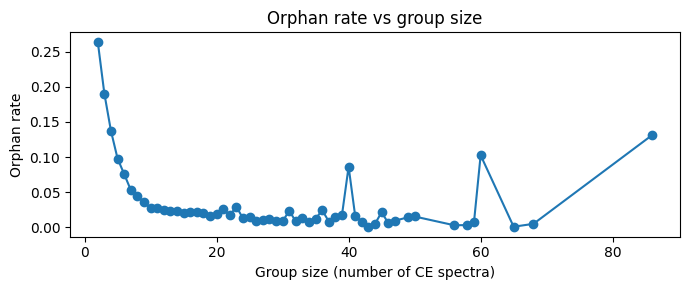

            orphan_rate  n_peaks
group_size                      
2                 0.264    41406
3                 0.190    61979
4                 0.137   112506
5                 0.098   257211
6                 0.076   318190
7                 0.053   418852
8                 0.044   605783
9                 0.036   831325
10                0.028  1236593
11                0.027  1436899
12                0.025  1745918
13                0.024  1797555
14                0.024  1711339
15                0.020  1825276
16                0.022   724823


In [ ]:
# ── 5. Orphan rate vs group size ──────────────────────────────────────────
# Larger groups are stricter: a peak must match in at least 1 of N-1 other spectra.
gs_stats = peak_df.groupby('group_size')['is_orphan'].agg(['mean', 'count'])
gs_stats.columns = ['orphan_rate', 'n_peaks']

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(gs_stats.index, gs_stats['orphan_rate'], marker='o')
ax.set_xlabel('Group size (number of CE spectra)')
ax.set_ylabel('Orphan rate')
ax.set_title('Orphan rate vs group size')
plt.tight_layout()
plt.show()

print(gs_stats.head(15).round(3))

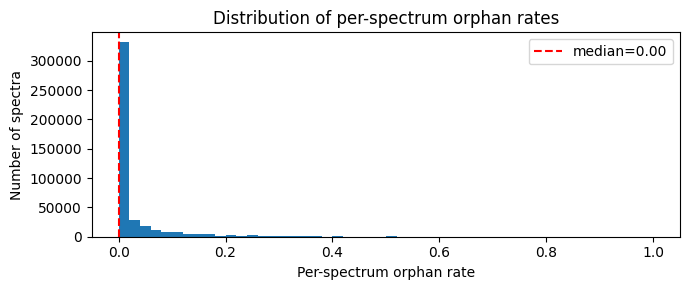

count    438792.000
mean          0.027
std           0.071
min           0.000
25%           0.000
50%           0.000
75%           0.019
max           1.000
Name: is_orphan, dtype: float64


In [ ]:
# ── 6. Per-spectrum orphan rate distribution ──────────────────────────────
spec_orphan = peak_df.groupby('spec_id')['is_orphan'].mean()

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(spec_orphan.values, bins=50, edgecolor='none')
ax.set_xlabel('Per-spectrum orphan rate')
ax.set_ylabel('Number of spectra')
ax.set_title('Distribution of per-spectrum orphan rates')
ax.axvline(spec_orphan.median(), color='red', linestyle='--', label=f'median={spec_orphan.median():.2f}')
ax.legend()
plt.tight_layout()
plt.show()

print(spec_orphan.describe().round(3))

In [ ]:
# ── 7. High-intensity orphans: suspicious candidates ─────────────────────
# These are the most interesting: high-intensity peaks that appear in only one CE.
# May indicate chimeric contamination, stepped precursor, or unusual fragmentation.
hi_orphans = peak_df[peak_df['is_orphan'] & (peak_df['rel_intensity'] > 0.1)].copy()
print(f"High-intensity orphans (rel_int > 0.1): {len(hi_orphans):,}  "
      f"({100*len(hi_orphans)/len(peak_df):.2f}% of all peaks)")
print()
print("By inst_type:")
print(hi_orphans.groupby('inst_type').size().sort_values(ascending=False).head(10))

High-intensity orphans (rel_int > 0.1): 3,316  (0.02% of all peaks)

By inst_type:
inst_type
FT      2978
QTOF     338
dtype: int64


In [ ]:
# ── 7. High-intensity orphans: suspicious candidates ─────────────────────
# These are the most interesting: high-intensity peaks that appear in only one CE.
# May indicate chimeric contamination, stepped precursor, or unusual fragmentation.
hi_orphans = peak_df[peak_df['is_orphan'] & (peak_df['rel_intensity'] > 0.5)].copy()
print(f"High-intensity orphans (rel_int > 0.5): {len(hi_orphans):,}  "
      f"({100*len(hi_orphans)/len(peak_df):.2f}% of all peaks)")
print()
print("By inst_type:")
print(hi_orphans.groupby('inst_type').size().sort_values(ascending=False).head(10))

High-intensity orphans (rel_int > 0.5): 246  (0.00% of all peaks)

By inst_type:
inst_type
FT      228
QTOF     18
dtype: int64
